In [1]:
import pandas as pd
import numpy as np
from src.data.metrics import get_metrics, exclude_tuning_samples

import matplotlib.ticker as mtick

import matplotlib.pyplot as plt

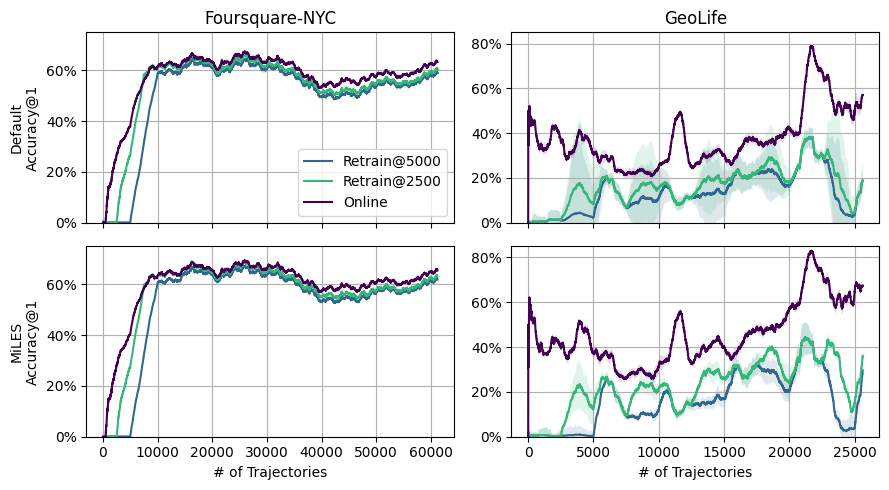

In [3]:
# Make retraining vs. online plots
df_online = pd.read_json("../reports/online_v_batch.jsonl", lines=True, orient="records")
# df_online["replay_buffer_type"] = df_online["replay_buffer_type"].fillna("none")
# df_online = df_online[
#     (df_online["replay_buffer_type"] == "none")
#     & (df_online["optimizer_cls"] == "Adam")
# ]

df_retrain = pd.read_json(
    "../reports/periodic_retrain.jsonl", lines=True, orient="records"
)
df_retrain["retrain_interval"] = (
    df_retrain
    .groupby(["dataset", "embedding_type"])["runtime"]
    .transform(lambda x: np.where(x > x.median(), 2500, 5000))
)

emb_names = {
    "lookup_sum": "Default",
    "lookup_concat": "Default",
    "lookup_weighted_concat": "MiLES",
}

for d in [df_online, df_retrain]:
    d.loc[:, "embedding_type"] = d["embedding_type"].apply(emb_names.get)
    d = d[d["embedding_type"].isin(["Default", "MiLES"])]

datasets = [
    ("foursquare_NYC", "Foursquare-NYC"),
    ("geolife", "GeoLife"),
]


intervals = [5000, 2500]
embeddings = ["Default", "MiLES"]

# One row per embedding, one column per dataset
fig, axs = plt.subplots(
    nrows=2, ncols=2, figsize=(9, 5), sharey="col", sharex='col'
)

cmap = plt.get_cmap("viridis", len(intervals) + 2)
online_color = cmap(0)
interval_colors = {iv: cmap(i + 1) for i, iv in enumerate(intervals)}

for col, (dataset_key, dataset_label) in enumerate(datasets):
    window = 5000 if dataset_key == "foursquare_NYC" else 1000

    for row, emb_type in enumerate(embeddings):
        ax = axs[row, col]

        # Plot periodic retraining runs
        for interval in intervals:
            dfp = df_retrain[
                (df_retrain["dataset"] == dataset_key)
                & (df_retrain["model_cls"] == "BiTULER")
                & (df_retrain["retrain_interval"] == interval)
                & (df_retrain["embedding_type"] == emb_type)
            ]

            rolling_top1_per_seed = []
            for seed, df_seed in dfp.groupby("seed"):
                labels = np.array(df_seed["labels"].item())
                preds = np.array(df_seed["preds"].item())
                top1 = (labels == preds).astype(float)
                rolling_top1 = pd.Series(top1).rolling(
                    window=window, min_periods=1
                ).mean()
                rolling_top1_per_seed.append(rolling_top1.values)

            if not rolling_top1_per_seed:
                continue

            rolling_top1 = np.vstack(rolling_top1_per_seed) * 100
            rolling_top1_mean = np.mean(rolling_top1, axis=0)
            rolling_top1_std = np.std(rolling_top1, axis=0) * 4
            x = np.arange(len(rolling_top1_mean))

            color = interval_colors[interval]
            ax.plot(
                rolling_top1_mean, color=color,
                label=f"Retrain@{interval}",
            )
            ax.fill_between(
                x,
                rolling_top1_mean - rolling_top1_std,
                rolling_top1_mean + rolling_top1_std,
                color=color, alpha=0.15, ec=None,
            )

        # Plot online learning
        dfp = df_online[
            (df_online["dataset"] == dataset_key)
            & (df_online["model_cls"] == "BiTULER")
            & (df_online["n_users"].isin([150, 800]))
            & (df_online["embedding_type"] == emb_type)
        ]

        rolling_top1_per_seed = []
        for seed, df_seed in dfp.groupby("seed"):
            labels = np.array(df_seed["labels"].item())
            preds = np.array(df_seed["preds"].item())
            top1 = (labels == preds).astype(float)
            rolling_top1 = pd.Series(top1).rolling(
                window=window, min_periods=1
            ).mean()
            rolling_top1_per_seed.append(rolling_top1.values)

        if rolling_top1_per_seed:
            rolling_top1 = np.vstack(rolling_top1_per_seed) * 100
            rolling_top1_mean = np.mean(rolling_top1, axis=0)
            rolling_top1_std = np.std(rolling_top1, axis=0) * 4
            x = np.arange(len(rolling_top1_mean))

            ax.plot(
                rolling_top1_mean, color=online_color,
                label="Online",
            )
            ax.fill_between(
                x,
                rolling_top1_mean - rolling_top1_std,
                rolling_top1_mean + rolling_top1_std,
                color=online_color, alpha=0.15, ec=None,
            )

        ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
        ax.grid()

        # Row labels
        if col == 0:
            ax.set_ylabel(f"{emb_type}\nAccuracy@1")

    axs[0, col].set_title(dataset_label)
    axs[-1, col].set_xlabel("# of Trajectories")
axs[0,1].set_ylim([0, 85])
axs[0,0].set_ylim([0, 75])
axs[0, 0].legend()
plt.tight_layout()
fig.savefig("../pub/figs/retraining.png", bbox_inches="tight", dpi=300)

In [ ]:
# emb_names = {
#     "lookup_concat": "Default",
#     "lookup_weighted_concat": "MiLES",
# }
# df_retrain["embedding_type"] = df_retrain["embedding_type"].map(emb_names)
df_online = pd.read_json("../reports/TUL.jsonl", lines=True, orient="records")
df_online["replay_buffer_type"] = df_online["replay_buffer_type"].fillna("none")
idcs_emb = df_online[
    (df_online["replay_buffer_type"] == "none") & (df_online["optimizer_cls"] == "Adam")
].index
df_online.loc[idcs_emb, "Type"] = "Embedding"
emb_names = {
    "lookup_sum": "Default",
    "lookup_concat": "Default",
    "lookup_weighted_concat": "MiLES",
    "fourier": "Fourier",
    "linear": "Linear",
}
df_online.loc[idcs_emb, "embedding_type"] = df_online.loc[idcs_emb, "embedding_type"].apply(emb_names.get)


df_online = df_online[
    (df_online["replay_buffer_type"] == "none")
    & (df_online["optimizer_cls"] == "Adam")
    & (df_online["model_cls"] == "BiTULER")
    & (df_online["n_users"].isin([150, 800]))
    & (df_online["Type"] == "Embedding")
    & (df_online["embedding_type"].isin(['Default', "MiLES"]))
]


# Add a retrain_interval column to online results for stacking
df_online["retrain_interval"] = 0  # 0 = online (every instance)

metrics = ["top_1_accuracy", "top_5_accuracy", "macro_f1"]
get_metrics(df_online, metrics)
get_metrics(df_retrain, metrics)

exclude_tuning_samples(df_online)

df_combined = pd.concat([df_retrain, df_online], ignore_index=True)
def highlight_max(s):
    """Highlight maximum value in bold for a Series."""
    is_max = s == s.max()
    return ["font-weight: bold" if v else "" for v in is_max]

dfm = (
    df_combined.groupby(
        ["dataset", "embedding_type", "retrain_interval" ]
    )[metrics]
    .mean()
    .reset_index()
)
dfm.loc[:, metrics] = dfm.loc[:, metrics] * 100

table = dfm.pivot_table(
    index=["embedding_type", "retrain_interval"],
    columns="dataset",
    values=["top_1_accuracy", "top_5_accuracy", 'macro_f1'],
).round(2)
table.columns = table.columns.reorder_levels([1, 0])
table = table.sort_index(axis=1)

# Sort so largest interval is first, online (0) is last
table = table.sort_index(
    level="embedding_type", ascending=False
)
table = table.reindex(metrics, axis=1, level=1)
table = table.rename(
    columns={
        "top_1_accuracy": "Acc@1",
        "top_5_accuracy": "Acc@5",
        "macro_f1": "Macro F1",
    }
)
table = table.rename(
    columns={
        "foursquare_NYC": "Foursquare-NYC",
        "foursquare_TKY": "Foursquare-TKY",
        "geolife": "GeoLife",
    }
)

print(
    table.style.format(precision=2)
    .apply(highlight_max)
    .to_latex(hrules=True, convert_css=True)
)

- online learning clearly outperforms retraining
- model begins to be useful earlier, since it doesn't have to wait for retraining interval but performance stays at a higher level throughout the whole stream, likely due to concept drift, which negatively affects the retraining approach in two ways:
- 1. retraining only begins to adapt the model once the interval is reached -> when retraining every 5000 trajectories, the model has an average "knowledge deficit" of 2500 trajectories
- 2. the old trajectories included in the full retraining dataset distract the model, since they're not representative of the current data distribution any more -> this seems to affect the performance especially for the GeoLife data, where the user distribution changes significantly over time
- MiLES also helps in the retraining regime
- it even narrows the gap, possibly since it helps compensate some of the knowledge deficit and bias towards previous data of the retrained models by allowing them to rely on the more general, aggregated/shared embeddings
- despite the advantage of being trained on all previously observed data for 10 epochs, the full retraining schedules performed notably worse compared to online learning, especially on GeoLife
- this is likely caused by the aforementioned effects
- with shorter retraining intervals, performance difference decreases, which supports our hypotheses
- however, full periodic retraining comes at a much larger computational and memory cost
- due to having to retrain on average with half of the full dataset several times and for several epoch, the computational cost of forward and backward passes for an interval of 2500 and 10 retraining epochs is 120 times larger than that of online learning on Foursquare-NYC (60k samples * 0.5 * (60k / 2500) retrainings * 10 epochs)